# FieldShift: which crops fit this county, in a dry, typical, or wet season?

NASA Space Apps Challenge 2026, "Adapting Farms with NASA Data". North Dakota prototype.

**What this notebook does**

1. Pulls county yields for 8 crops from USDA NASS (2010 to 2025).
2. Pulls daily weather for every county from NASA POWER (2010 to 2025).
3. Trains one model per crop and tests it the honest way: train on past years, test on a later year it never saw.
4. Turns the model into a "what if" tool: expected yield in a dry, typical, or wet season, at today's yield level.
5. Writes `docs/data.js`, the file the web app reads.

**What it is not:** a forecast. The model needs the whole season's weather, which nobody has at planting time. That is why the app asks "what kind of season?" and never claims to know.

Every download is cached in `data/raw`, so a second run is fast and works offline.

In [1]:
import sys, json, time, warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore", category=FutureWarning)

# In Colab: paste the GitHub repo URL here to reuse the cached data files.
# Leave it empty to download everything fresh (about 5 minutes).
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and REPO_URL and not Path("data/raw").exists():
    import subprocess, os
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "fieldshift_repo"], check=True)
    os.chdir("fieldshift_repo")

ROOT = Path(".")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
DOCS = ROOT / "docs"
POWER_CACHE = RAW / "power_cache"
for folder in [RAW, PROCESSED, DOCS, POWER_CACHE]:
    folder.mkdir(parents=True, exist_ok=True)

FIRST_YEAR, LAST_YEAR = 2010, 2025
YEARS = list(range(FIRST_YEAR, LAST_YEAR + 1))
print("Working in:", ROOT.resolve())

Working in: /home/claude/fieldshift


## 1. Crops

One entry per crop: the exact USDA "Data Item" for yield and for price, the unit, and what equipment the crop usually needs. The equipment tags drive the filters in the app. They are general rules of thumb, not data.

In [2]:
CROPS = {
    "spring_wheat": dict(
        label="Spring wheat", unit="bu/acre",
        item="WHEAT, SPRING, (EXCL DURUM) - YIELD, MEASURED IN BU / ACRE",
        price_item="WHEAT, SPRING, (EXCL DURUM) - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "durum": dict(
        label="Durum wheat", unit="bu/acre",
        item="WHEAT, SPRING, DURUM - YIELD, MEASURED IN BU / ACRE",
        price_item="WHEAT, SPRING, DURUM - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "barley": dict(
        label="Barley", unit="bu/acre",
        item="BARLEY - YIELD, MEASURED IN BU / ACRE",
        price_item="BARLEY - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill"]),
    "canola": dict(
        label="Canola", unit="lb/acre",
        item="CANOLA - YIELD, MEASURED IN LB / ACRE",
        price_item="CANOLA - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["drill"]),
    "dry_peas": dict(
        label="Dry peas", unit="lb/acre",
        item="PEAS, DRY EDIBLE - YIELD, MEASURED IN LB / ACRE",
        price_item="PEAS, DRY EDIBLE - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["drill"]),
    "soybeans": dict(
        label="Soybeans", unit="bu/acre",
        item="SOYBEANS - YIELD, MEASURED IN BU / ACRE",
        price_item="SOYBEANS - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["drill_or_planter"]),
    "corn": dict(
        label="Corn (grain)", unit="bu/acre",
        item="CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",
        price_item="CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU", price_div=1,
        needs=["planter", "corn_head"]),
    "sunflower": dict(
        label="Sunflower (oil)", unit="lb/acre",
        item="SUNFLOWER, OIL TYPE - YIELD, MEASURED IN LB / ACRE",
        price_item="SUNFLOWER, OIL TYPE - PRICE RECEIVED, MEASURED IN $ / CWT", price_div=100,
        needs=["planter"]),
}

## 2. USDA NASS yields and prices

This uses the same route as the Quick Stats website's "Spreadsheet" button, so no API key is needed. If USDA ever blocks it, run the query by hand at quickstats.nass.usda.gov, click Spreadsheet, and save the file under the cache name printed below.

In [3]:
NASS = "https://quickstats.nass.usda.gov"
HEADERS = {"User-Agent": "Mozilla/5.0 (FieldShift student project)"}

def nass_table(filters, years, cache_file):
    """Download one Quick Stats query as a table. Cached on disk."""
    if cache_file.exists():
        return pd.read_csv(cache_file, dtype=str)
    form = list(filters.items()) + [("year", str(y)) for y in years]
    uuid = requests.post(f"{NASS}/uuid/encode", data=form, headers=HEADERS, timeout=120)
    uuid.raise_for_status()
    uuid = uuid.text.strip().strip('"')
    csv = requests.get(f"{NASS}/data/spreadsheet/{uuid}.csv", headers=HEADERS, timeout=300)
    csv.raise_for_status()
    cache_file.write_bytes(csv.content)
    return pd.read_csv(cache_file, dtype=str)

yield_raw = nass_table(
    {"source_desc": "SURVEY", "sector_desc": "CROPS", "group_desc": "FIELD CROPS",
     "statisticcat_desc": "YIELD", "agg_level_desc": "COUNTY", "state_name": "NORTH DAKOTA"},
    YEARS, RAW / "nass_nd_field_crop_yields_2010_2025.csv")

price_raw = nass_table(
    {"source_desc": "SURVEY", "sector_desc": "CROPS", "group_desc": "FIELD CROPS",
     "statisticcat_desc": "PRICE RECEIVED", "agg_level_desc": "STATE",
     "state_name": "NORTH DAKOTA", "freq_desc": "ANNUAL"},
    range(2021, LAST_YEAR + 1), RAW / "nass_nd_prices_2021_2025.csv")

print("Yield rows:", len(yield_raw), "| Price rows:", len(price_raw))

Yield rows: 6479 | Price rows: 146


In [4]:
def to_number(series):
    return pd.to_numeric(series.astype(str).str.replace(",", "", regex=False), errors="coerce")

item_to_crop = {c["item"]: key for key, c in CROPS.items()}

y = yield_raw[yield_raw["Data Item"].isin(item_to_crop)].copy()
# Rows without a county code are "OTHER COUNTIES" lumps. They are not one place, so drop them.
y = y[y["County ANSI"].notna() & (y["Period"] == "YEAR")].copy()

yields = pd.DataFrame({
    "year": y["Year"].astype(int),
    "county_fips": y["State ANSI"].str.zfill(2) + y["County ANSI"].str.zfill(3),
    "county": y["County"].str.strip().str.title(),
    "crop": y["Data Item"].map(item_to_crop),
    "yield": to_number(y["Value"]),
}).dropna(subset=["yield"]).reset_index(drop=True)

assert not yields.duplicated(["crop", "county_fips", "year"]).any(), "duplicate county-year rows"

coverage = yields.pivot_table(index="crop", columns="year", values="yield", aggfunc="size").fillna(0).astype(int)
print("Counties reporting, by crop and year:")
display(coverage)

Counties reporting, by crop and year:


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
crop,,,,,,,,,,,,,,,,
barley,41,27,31,10,34,18,36,33,21,18,27,24,25,20,0,16
canola,35,31,25,15,13,14,26,28,15,13,27,25,31,26,25,19
corn,45,45,47,32,33,36,43,34,24,21,45,45,44,48,42,31
dry_peas,26,8,9,5,4,12,27,13,10,4,15,12,8,9,6,6
durum,18,10,8,2,6,5,15,15,9,5,18,18,12,14,0,11
soybeans,35,33,32,27,33,32,36,39,35,34,48,46,45,42,40,35
spring_wheat,51,45,39,19,42,33,36,38,40,30,50,47,48,42,0,36
sunflower,36,28,23,9,15,14,14,16,11,0,33,27,25,17,10,10


Two things to notice in that table:

* USDA only publishes a county when enough farms report, so the number of counties changes every year.
* Small grains (wheat, durum, barley) have no county numbers for 2024. Row crops do.

In [5]:
p = price_raw[(price_raw["Period"] == "MARKETING YEAR")].copy()
p["price"] = to_number(p["Value"])
p["year"] = p["Year"].astype(int)

prices = {}
for key, c in CROPS.items():
    rows = p[p["Data Item"] == c["price_item"]].dropna(subset=["price"]).sort_values("year")
    assert len(rows), f"no price found for {key}"
    last = rows.iloc[-1]
    prices[key] = dict(price=round(float(last["price"]) / c["price_div"], 4), year=int(last["year"]))

price_table = pd.DataFrame(prices).T
price_table["per"] = [CROPS[k]["unit"].split("/")[0] for k in price_table.index]
print("North Dakota average price received, latest marketing year (USDA NASS):")
display(price_table)

North Dakota average price received, latest marketing year (USDA NASS):


,price,year,per
spring_wheat,5.330,2025.0,bu
durum,6.100,2025.0,bu
barley,4.760,2025.0,bu
canola,0.212,2025.0,lb
dry_peas,0.112,2025.0,lb
soybeans,9.790,2025.0,bu
corn,3.800,2025.0,bu
sunflower,0.237,2025.0,lb


## 3. County locations

County centers come from the US Census gazetteer. Each county is matched to the nearest NASA POWER weather cell (0.5 degrees of latitude by 0.625 degrees of longitude).

In [6]:
gaz_file = RAW / "2024_gaz_counties_38.txt"
if not gaz_file.exists():
    url = "https://www2.census.gov/geo/docs/maps-data/data/gazetteer/2024_Gazetteer/2024_gaz_counties_38.txt"
    gaz_file.write_bytes(requests.get(url, headers=HEADERS, timeout=120).content)

counties = pd.read_csv(gaz_file, sep="\t", dtype={"GEOID": str})
counties.columns = counties.columns.str.strip()
counties = counties.rename(columns={"GEOID": "county_fips", "NAME": "name",
                                    "INTPTLAT": "latitude", "INTPTLONG": "longitude"})
counties["name"] = counties["name"].str.replace(" County", "", regex=False).str.strip()
counties = counties[["county_fips", "name", "latitude", "longitude"]]
counties["grid_lat"] = (counties["latitude"] / 0.5).round() * 0.5
counties["grid_lon"] = (counties["longitude"] / 0.625).round() * 0.625

grids = counties[["grid_lat", "grid_lon"]].drop_duplicates().reset_index(drop=True)
print("Counties:", len(counties), "| Weather cells:", len(grids))

Counties: 53 | Weather cells: 52


## 4. NASA POWER daily weather

One request per weather cell, 2010 to 2025. Only April to September is kept, because that is the growing season the features use.

In [7]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
POWER_PARAMS = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR", "ALLSKY_SFC_SW_DWN", "RH2M", "WS10M"]

def power_daily(lat, lon):
    """April to September daily weather for one cell. Cached on disk."""
    cache_file = POWER_CACHE / f"power_{lat:.3f}_{lon:.3f}.csv"
    if cache_file.exists():
        return pd.read_csv(cache_file, parse_dates=["DATE"])
    response = requests.get(POWER_URL, timeout=180, params={
        "parameters": ",".join(POWER_PARAMS), "community": "AG",
        "latitude": lat, "longitude": lon,
        "start": f"{FIRST_YEAR}0101", "end": f"{LAST_YEAR}1231",
        "format": "JSON", "time-standard": "UTC"})
    response.raise_for_status()
    daily = pd.DataFrame(response.json()["properties"]["parameter"])
    daily.index = pd.to_datetime(daily.index, format="%Y%m%d")
    daily.index.name = "DATE"
    daily = daily[daily.index.month.isin(range(4, 10))].reset_index()
    daily.to_csv(cache_file, index=False)
    time.sleep(0.5)
    return daily

weather_rows = []
for cell in grids.itertuples(index=False):
    daily = power_daily(cell.grid_lat, cell.grid_lon)
    daily[POWER_PARAMS] = daily[POWER_PARAMS].replace(-999, np.nan)   # NASA's missing value marker
    season = daily[daily["DATE"].dt.month.between(5, 9)]             # May to September
    for year, g in season.groupby(season["DATE"].dt.year):
        weather_rows.append({
            "grid_lat": cell.grid_lat, "grid_lon": cell.grid_lon, "year": int(year),
            "avg_temp_c": g["T2M"].mean(),
            "total_rain_mm": g["PRECTOTCORR"].sum(min_count=1),
            "heat_days_30c": int((g["T2M_MAX"] >= 30).sum()),
            "avg_solar": g["ALLSKY_SFC_SW_DWN"].mean(),
            "avg_humidity": g["RH2M"].mean(),
            "avg_wind": g["WS10M"].mean(),
            "valid_days": int(g[["T2M", "PRECTOTCORR"]].notna().all(axis=1).sum()),
        })

weather = pd.DataFrame(weather_rows)
weather = weather[weather["valid_days"] >= 140].drop(columns="valid_days")
county_weather = counties.merge(weather, on=["grid_lat", "grid_lon"], how="left")

print("Cell-years of weather:", len(weather))
print("Missing values:", int(weather.isna().sum().sum()))
display(weather.groupby("year")[["total_rain_mm", "heat_days_30c", "avg_temp_c"]].mean().round(1).T)

Cell-years of weather: 832
Missing values: 0


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
total_rain_mm,455.1,425.1,221.1,413.1,394.5,347.6,367.1,269.2,323.6,462.7,270.2,255.8,307.1,341.2,358.2,370.3
heat_days_30c,25.0,21.0,51.7,26.1,12.9,37.1,32.6,40.2,40.7,22.2,33.9,62.8,39.6,38.6,37.7,33.5
avg_temp_c,17.3,17.4,19.3,18.1,16.9,18.4,18.7,18.5,19.1,17.4,18.4,20.3,18.7,19.9,19.2,19.1


2012, 2017, 2020 and 2021 were the driest seasons, and 2021 was also the hottest by a wide margin. Years like those are where a weather model has to earn its keep.

## 5. Training table

In [8]:
WEATHER_FEATURES = ["avg_temp_c", "total_rain_mm", "heat_days_30c", "avg_solar", "avg_humidity", "avg_wind"]
FEATURES = ["latitude", "longitude"] + WEATHER_FEATURES

data = yields.merge(county_weather.drop(columns=["name"]), on=["county_fips", "year"], how="left", validate="many_to_one")
print("Rows without weather:", int(data[FEATURES].isna().any(axis=1).sum()))
data = data.dropna(subset=FEATURES).reset_index(drop=True)
data.to_csv(PROCESSED / "fieldshift_training_multicrop.csv", index=False)

display(data.groupby("crop").agg(rows=("yield", "size"), counties=("county_fips", "nunique"),
                                 years=("year", "nunique"), mean_yield=("yield", "mean")).round(1))

Rows without weather: 0


,rows,counties,years,mean_yield
crop,,,,
barley,381,51,15,64.7
canola,368,42,16,1669.0
corn,615,53,16,117.2
dry_peas,174,41,16,2234.6
durum,166,38,15,38.6
soybeans,592,51,16,32.4
spring_wheat,596,53,15,45.8
sunflower,288,49,15,1666.7


## 6. Models and honest testing

Four ways to predict a county's yield:

* **County average.** The county's own average over all training years. This is the bar to beat.
* **Recent median.** The county's middle value over the last 6 training years. No weather, no model, just "what has this county done lately".
* **Forest.** A random forest on location plus season weather (the v2 setup from the first notebook).
* **Forest + trend.** Same forest, but it predicts yield relative to the statewide trend line. Yields climb over time as seed and practices improve, and a plain forest can never predict above what it has already seen. That is why v2 came in low in 35 of 36 counties in 2025.

**The test:** for each year from 2016 to 2024, train only on earlier years, then predict that year. No number below comes from data the model saw. 2025 is kept out of all of this and used once at the end.

In [9]:
def make_forest():
    return RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1)

def fit_trend(train):
    """Statewide yield trend. Theil-Sen line, so one drought year cannot tilt it."""
    means = train.groupby("year")["yield"].mean()
    x, v = means.index.to_numpy(float), means.to_numpy(float)
    slopes = [(v[j] - v[i]) / (x[j] - x[i]) for i in range(len(x)) for j in range(i + 1, len(x))]
    slope = float(np.median(slopes)) if slopes else 0.0
    intercept = float(np.median(v - slope * x))
    floor = 0.5 * float(np.median(v))
    return lambda years: np.maximum(intercept + slope * np.asarray(years, float), floor)

def predict_all(train, test_features, test_years, test_fips):
    """Predictions from all four methods for the rows described by the test arguments."""
    county_mean = train.groupby("county_fips")["yield"].mean()
    out = {"County average": pd.Series(test_fips).map(county_mean).fillna(train["yield"].mean()).to_numpy()}

    recent = train[train["year"] >= train["year"].max() - 5]
    recent_median = recent.groupby("county_fips")["yield"].median()
    out["Recent median"] = pd.Series(test_fips).map(recent_median).fillna(recent["yield"].median()).to_numpy()

    forest = make_forest().fit(train[FEATURES], train["yield"])
    out["Forest"] = forest.predict(test_features)

    trend = fit_trend(train)
    ratio_forest = make_forest().fit(train[FEATURES], train["yield"] / trend(train["year"]))
    out["Forest + trend"] = ratio_forest.predict(test_features) * trend(test_years)
    return out

fold_rows = []
for crop in CROPS:
    d = data[data["crop"] == crop]
    for test_year in range(2016, 2025):
        train, test = d[d["year"] < test_year], d[d["year"] == test_year]
        if len(test) < 5 or train["year"].nunique() < 5:
            continue
        preds = predict_all(train, test[FEATURES], test["year"], test["county_fips"].to_numpy())
        for model, pred in preds.items():
            err = pred - test["yield"].to_numpy()
            fold_rows.append({"crop": crop, "year": test_year, "model": model, "n": len(test),
                              "MAE": np.abs(err).mean(), "bias": err.mean(),
                              "mean_yield": test["yield"].mean()})

folds = pd.DataFrame(fold_rows)
folds.to_csv(PROCESSED / "fieldshift_forward_validation.csv", index=False)
print("Test folds:", folds.groupby("crop")["year"].nunique().to_dict())

Test folds: {'barley': 8, 'canola': 9, 'corn': 9, 'dry_peas': 8, 'durum': 8, 'soybeans': 9, 'spring_wheat': 8, 'sunflower': 8}


In [10]:
MODELS = ["County average", "Recent median", "Forest", "Forest + trend"]

summary = folds.pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS]
mean_yield = folds.groupby("crop")["mean_yield"].mean()
summary_pct = summary.div(mean_yield, axis=0) * 100

print("Average error on unseen years, 2016 to 2024 (in each crop's own unit):")
display(summary.loc[list(CROPS)].round(1))
print("Same thing as a percent of the crop's average yield:")
display(summary_pct.loc[list(CROPS)].round(1))

Average error on unseen years, 2016 to 2024 (in each crop's own unit):


model,County average,Recent median,Forest,Forest + trend
crop,,,,
spring_wheat,7.0,6.7,6.6,6.4
durum,9.9,11.0,8.2,8.8
barley,10.2,10.0,10.2,10.3
canola,292.3,299.9,244.7,211.5
dry_peas,509.5,534.3,501.5,497.0
soybeans,5.4,5.6,5.9,6.1
corn,19.8,20.8,19.9,21.3
sunflower,350.7,303.9,292.9,354.6


Same thing as a percent of the crop's average yield:


model,County average,Recent median,Forest,Forest + trend
crop,,,,
spring_wheat,15.0,14.4,14.3,13.8
durum,24.6,27.2,20.3,21.9
barley,15.1,14.8,15.1,15.2
canola,16.9,17.4,14.2,12.3
dry_peas,21.5,22.5,21.1,20.9
soybeans,16.3,17.2,18.0,18.7
corn,16.3,17.2,16.4,17.5
sunflower,19.4,16.8,16.2,19.6


In [11]:
# Pick ONE weather model for every crop, using only the 2016 to 2024 tests. 2025 has not been looked at yet.
relative = summary[["Forest", "Forest + trend"]].div(summary["County average"], axis=0)
print("Error relative to the county average (below 1.0 is better):")
display(relative.loc[list(CROPS)].round(2))
print(relative.mean().round(3).to_string())

CHOSEN = relative.mean().idxmin()
print("\nChosen weather model:", CHOSEN)

Error relative to the county average (below 1.0 is better):


model,Forest,Forest + trend
crop,,
spring_wheat,0.95,0.92
durum,0.83,0.89
barley,1.00,1.01
canola,0.84,0.72
dry_peas,0.98,0.98
soybeans,1.10,1.15
corn,1.01,1.08
sunflower,0.84,1.01


model
Forest            0.943
Forest + trend    0.969

Chosen weather model: Forest


### What the tests say

* Averaged over the 8 crops, the forest's error is about 6% lower than the county average. That is a small edge.
* It clearly helps for canola, durum and sunflower (about 16% lower error), roughly ties for barley, corn and dry peas, and is worse for soybeans.
* The trend version does better in most ordinary years and worse in drought years (next table), so it loses overall. The plain forest is the weather model from here on.
* Typical error is 14 to 21% of yield, depending on the crop. Treat every number as a rough guide.

In [12]:
dry = folds[folds["year"].isin([2017, 2021])].pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS]
normal = folds[~folds["year"].isin([2017, 2021])].pivot_table(index="crop", columns="model", values="MAE", aggfunc="mean")[MODELS]
dry_pct = dry.div(mean_yield, axis=0) * 100
print("Error in the two drought years of the test window (2017, 2021), as % of average yield:")
display(dry_pct.loc[list(CROPS)].round(1))
print("Error in the other years, as % of average yield:")
display((normal.div(mean_yield, axis=0) * 100).loc[list(CROPS)].round(1))

Error in the two drought years of the test window (2017, 2021), as % of average yield:


model,County average,Recent median,Forest,Forest + trend
crop,,,,
spring_wheat,22.6,24.5,19.6,23.2
durum,27.1,29.3,26.5,34.1
barley,21.0,21.3,19.1,23.4
canola,23.4,28.1,14.2,15.7
dry_peas,30.5,34.7,27.3,36.3
soybeans,19.4,21.1,26.0,26.7
corn,20.0,23.6,20.6,29.7
sunflower,17.5,17.0,16.2,29.8


Error in the other years, as % of average yield:


model,County average,Recent median,Forest,Forest + trend
crop,,,,
spring_wheat,12.5,11.0,12.5,10.7
durum,23.8,26.5,18.3,17.8
barley,13.1,12.7,13.7,12.5
canola,15.1,14.3,14.2,11.3
dry_peas,18.4,18.4,19.1,15.8
soybeans,15.4,16.1,15.7,16.5
corn,15.2,15.3,15.2,14.1
sunflower,20.0,16.7,16.2,16.2


## 7. The 2025 check

Train on everything through 2024, predict 2025 once. 2025 set records in many counties, so it is a hard test.

In [13]:
holdout_rows, holdout_preds = [], []
for crop in CROPS:
    d = data[data["crop"] == crop]
    train, test = d[d["year"] <= 2024], d[d["year"] == 2025]
    if len(test) < 5:
        continue
    preds = predict_all(train, test[FEATURES], test["year"], test["county_fips"].to_numpy())
    for model, pred in preds.items():
        err = pred - test["yield"].to_numpy()
        holdout_rows.append({"crop": crop, "model": model, "n": len(test), "MAE": np.abs(err).mean(),
                             "bias": err.mean(), "pct_of_yield": 100 * np.abs(err).mean() / test["yield"].mean(),
                             "predicted_low_in": int((err < 0).sum())})
    holdout_preds.append(test[["crop", "county", "yield"]].assign(predicted=preds[CHOSEN]))

holdout = pd.DataFrame(holdout_rows)
holdout.to_csv(PROCESSED / "fieldshift_holdout_2025.csv", index=False)
display(holdout.set_index(["crop", "model"]).round(1))

n    MAE   bias  pct_of_yield  predicted_low_in
crop         model                                                           
spring_wheat County average  36   10.3  -10.3          18.3                36
             Recent median   36    8.0   -7.8          14.2                34
             Forest          36    7.6   -7.6          13.6                36
             Forest + trend  36    5.5   -5.5           9.8                33
durum        County average  11    8.9   -8.9          19.5                11
             Recent median   11    7.2   -6.5          15.8                10
             Forest          11    3.3   -2.6           7.2                 9
             Forest + trend  11    3.6    2.2           7.9                 3
barley       County average  16   13.5  -13.5          16.8                16
             Recent median   16    9.9   -9.9          12.3                16
             Forest          16    7.0   -6.4           8.7                15
             Forest + trend  16    3.1   -0.4           3.9                 9
canola       County average  19  451.8 -451.8          21.5                19
             Recent median   19  331.6 -331.6          15.8                19
             Forest          19  290.4 -279.2          13.8                18
             Forest + trend  19  221.9 -192.3          10.5                16
dry_peas     County average   6  243.3  -33.3          11.6                 4
             Recent median    6  252.5  207.5          12.1                 1
             Forest           6  231.8  224.7          11.1                 1
             Forest + trend   6  498.3  498.3          23.9                 0
soybeans     County average  35    2.9   -1.7           8.4                25
             Recent median   35    3.3   -1.5           9.6                23
             Forest          35    3.1   -0.2           9.0                19
             Forest + trend  35    3.0    0.0           9.0                18
corn         County average  31   28.8  -28.8          19.4                31
             Recent median   31   23.4  -23.4          15.7                31
             Forest          31   21.8  -21.3          14.7                30
             Forest + trend  31   15.8  -13.5          10.6                27
sunflower    County average  10  366.4 -289.4          18.2                 7
             Recent median   10  357.5 -149.5          17.8                 7
             Forest          10  335.9 -219.9          16.7                 6
             Forest + trend  10  330.4  -38.2          16.4                 5

### What 2025 says

* 2025 was a very strong year, and every method came in low for most crops. The forest was low in all 36 spring wheat counties.
* The forest still beat the county average for 7 of the 8 crops. Soybeans is the exception.
* The trend version was the closest for wheat, barley, canola, corn and sunflower. It stays unchosen: the pick was fixed from the 2016 to 2024 tests before 2025 was opened, and switching now would be choosing on the test.
* Takeaway for the app: the model's level runs low in a strong year. So the app takes the typical level from recent reports and uses the model only for the dry and wet change.

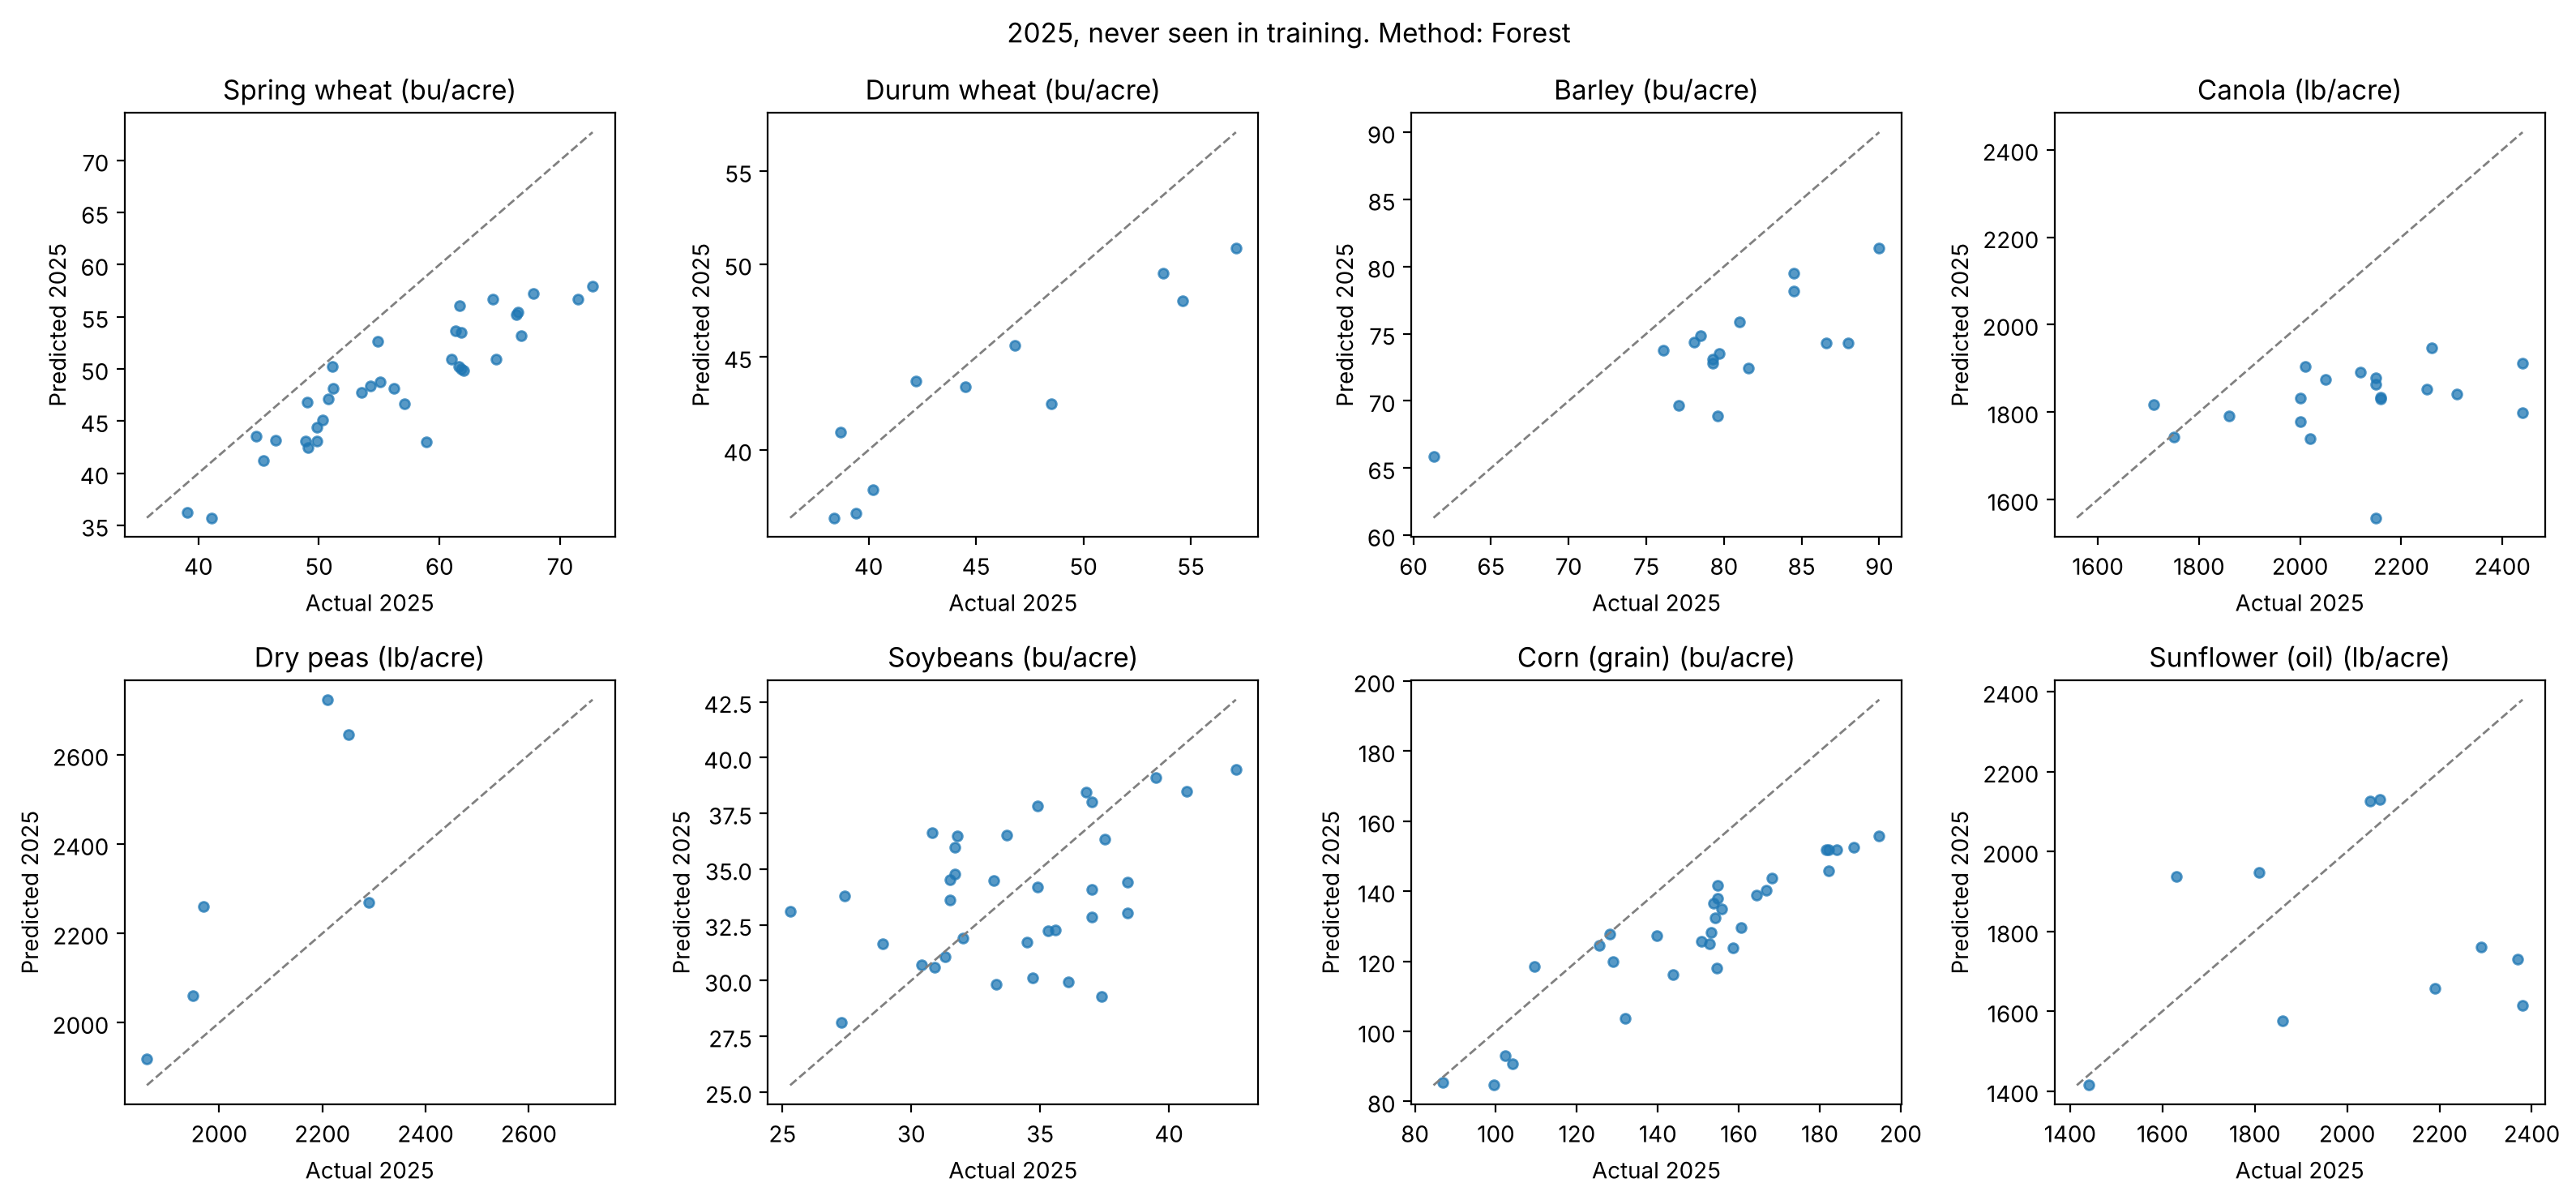

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, part in zip(axes.ravel(), holdout_preds):
    crop = part["crop"].iloc[0]
    ax.scatter(part["yield"], part["predicted"], s=18, alpha=0.75)
    lo, hi = min(part["yield"].min(), part["predicted"].min()), max(part["yield"].max(), part["predicted"].max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="gray", linewidth=1)
    ax.set_title(f"{CROPS[crop]['label']} ({CROPS[crop]['unit']})")
    ax.set_xlabel("Actual 2025"); ax.set_ylabel("Predicted 2025")
fig.suptitle(f"2025, never seen in training. Method: {CHOSEN}")
fig.tight_layout()
plt.show()

## 8. From model to "what if": dry, typical, and wet seasons

For every county, the 16 seasons are sorted by May to September rainfall at that county:

* **Dry** = the 4 driest seasons
* **Typical** = the 8 in the middle
* **Wet** = the 4 wettest

The app's numbers are built in two parts, so each part does the job it is good at:

* **Level (the "typical" number):** the county's middle reported yield for 2020 to 2025. That is real data at today's yield level. If a county has fewer than 3 reports in that window, the level is the model's typical value scaled by the statewide ratio, and the app marks it as an estimate.
* **Season effect (dry or wet):** the weather model's percent change from typical. To get the model's answer for year Y, it is trained on every year **except** Y, so it never gets to memorize the answer.

A crop is only shown for a county if USDA reported it there in at least 4 of the 16 years. No reports usually means few farms grow it there.

In [15]:
MIN_REPORTED_YEARS = 4

def scenario_predictions(crop):
    d = data[data["crop"] == crop]
    reported = d.groupby("county_fips")["year"].nunique()
    grown = reported[reported >= MIN_REPORTED_YEARS].index
    targets = county_weather[county_weather["county_fips"].isin(grown)].dropna(subset=FEATURES)
    rows = []
    for year in YEARS:
        train = d[d["year"] != year]
        test = targets[targets["year"] == year]
        if test.empty:
            continue
        if CHOSEN == "Forest + trend":
            trend = fit_trend(train)
            model = make_forest().fit(train[FEATURES], train["yield"] / trend(train["year"]))
            pred = model.predict(test[FEATURES]) * trend([LAST_YEAR])[0]      # today's yield level
        elif CHOSEN == "Forest":
            pred = make_forest().fit(train[FEATURES], train["yield"]).predict(test[FEATURES])
        else:
            pred = test["county_fips"].map(train.groupby("county_fips")["yield"].mean()).to_numpy()
        rows.append(pd.DataFrame({"crop": crop, "county_fips": test["county_fips"].to_numpy(),
                                  "year": year, "predicted": pred}))
    return pd.concat(rows, ignore_index=True)

scenario_long = pd.concat([scenario_predictions(crop) for crop in CROPS], ignore_index=True)

# Season group for every county and year, from that county's own rainfall ranking
rain = county_weather.dropna(subset=["total_rain_mm"])[["county_fips", "year", "total_rain_mm"]].copy()
rain["rank"] = rain.groupby("county_fips")["total_rain_mm"].rank(method="first")
rain["season"] = np.select([rain["rank"] <= 4, rain["rank"] > len(YEARS) - 4], ["dry", "wet"], default="typical")

scenario_long = scenario_long.merge(rain[["county_fips", "year", "season"]], on=["county_fips", "year"])
scenarios = scenario_long.pivot_table(index=["crop", "county_fips"], columns="season", values="predicted", aggfunc="mean").reset_index()
scenarios["dry_change"] = scenarios["dry"] / scenarios["typical"] - 1
scenarios["wet_change"] = scenarios["wet"] / scenarios["typical"] - 1

# Level: middle reported yield, 2020 to 2025, where the county has at least 3 reports
recent = data[data["year"] >= LAST_YEAR - 5]
level = recent.groupby(["crop", "county_fips"])["yield"].agg(recent_median="median", recent_reports="size").reset_index()
scenarios = scenarios.merge(level, on=["crop", "county_fips"], how="left")
has_level = scenarios["recent_reports"].fillna(0) >= 3
state_ratio = (scenarios[has_level].assign(r=lambda t: t["recent_median"] / t["typical"]).groupby("crop")["r"].median())
scenarios["level_source"] = np.where(has_level, "reports", "estimate")
scenarios["level"] = np.where(has_level, scenarios["recent_median"], scenarios["typical"] * scenarios["crop"].map(state_ratio))
scenarios["level_dry"] = scenarios["level"] * (1 + scenarios["dry_change"])
scenarios["level_wet"] = scenarios["level"] * (1 + scenarios["wet_change"])
scenarios.to_csv(PROCESSED / "fieldshift_scenarios.csv", index=False)

print("Recent level divided by the model's typical value (how far yields have moved up):")
print(state_ratio.loc[list(CROPS)].round(2).to_string())
print("\nCounty-crop pairs:", len(scenarios), "| level from reports:", int(has_level.sum()), "| estimated:", int((~has_level).sum()))

state_view = scenarios.groupby("crop")[["dry", "typical", "wet"]].mean().loc[list(CROPS)]
state_view["dry vs typical %"] = (state_view["dry"] / state_view["typical"] - 1) * 100
state_view["wet vs typical %"] = (state_view["wet"] / state_view["typical"] - 1) * 100
print("\nModel output, average across counties:")
display(state_view.round(1))

Recent level divided by the model's typical value (how far yields have moved up):
crop
spring_wheat    1.04
durum           1.01
barley          1.04
canola          1.04
dry_peas        1.02
soybeans        1.00
corn            1.02
sunflower       1.11

County-crop pairs: 304 | level from reports: 228 | estimated: 76

Model output, average across counties:


,dry,typical,wet,dry vs typical %,wet vs typical %
crop,,,,,
spring_wheat,43.7,46.5,45.2,-6.0,-2.7
durum,35.4,41.6,40.2,-14.9,-3.4
barley,60.6,66.4,63.9,-8.7,-3.7
canola,1539.8,1745.5,1718.0,-11.8,-1.6
dry_peas,2227.4,2288.8,2198.0,-2.7,-4.0
soybeans,30.4,32.8,33.5,-7.1,2.3
corn,105.1,116.2,115.3,-9.5,-0.7
sunflower,1783.3,1734.5,1505.9,2.8,-13.2


### Sanity check on the scenarios

The scenario numbers come from the model. Do real yields show the same pattern? Below: actual reported yields, divided by the trend so old and new years compare fairly, averaged by season group.

In [16]:
check_rows = []
for crop in CROPS:
    d = data[data["crop"] == crop].merge(rain[["county_fips", "year", "season"]], on=["county_fips", "year"])
    trend = fit_trend(d)
    d = d.assign(relative=d["yield"] / trend(d["year"]))
    actual = d.groupby("season")["relative"].mean()
    model = state_view.loc[crop]
    check_rows.append({"crop": crop,
                       "actual dry vs typical %": (actual["dry"] / actual["typical"] - 1) * 100,
                       "model dry vs typical %": model["dry vs typical %"],
                       "actual wet vs typical %": (actual["wet"] / actual["typical"] - 1) * 100,
                       "model wet vs typical %": model["wet vs typical %"]})
check = pd.DataFrame(check_rows).set_index("crop")
display(check.round(1))

,actual dry vs typical %,model dry vs typical %,actual wet vs typical %,model wet vs typical %
crop,,,,
spring_wheat,-6.5,-6.0,-2.0,-2.7
durum,-20.3,-14.9,2.4,-3.4
barley,-9.4,-8.7,1.0,-3.7
canola,-16.1,-11.8,-0.2,-1.6
dry_peas,-1.0,-2.7,1.2,-4.0
soybeans,-10.2,-7.1,4.4,2.3
corn,-12.4,-9.5,5.2,-0.7
sunflower,3.9,2.8,-6.1,-13.2


In a dry season the model gets the direction right for every crop, and it understates the size of the loss for durum, canola, soybeans and corn. For wet seasons the model and the reports point in different directions for durum, barley, dry peas and corn, so the wet numbers are the weakest part of the app.

One more caution: "dry" here means the 4 lowest rainfall seasons at that county. A drought that is also very hot, like 2021, hits harder than this average. The app shows each county's worst reported year next to the dry estimate for that reason.

## 9. Write the app's data file

Everything the web page needs goes into `docs/data.js`: crops, prices, test results, county scenarios, reported history, and the county outlines for the map.

In [17]:
geo_file = RAW / "nd_counties.geojson"
if not geo_file.exists():
    url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
    us = requests.get(url, timeout=120).json()
    nd = [f for f in us["features"] if f["properties"]["STATE"] == "38"]
    geo_file.write_text(json.dumps({"type": "FeatureCollection", "features": [
        {"type": "Feature", "id": f["id"], "properties": {"fips": f["id"], "name": f["properties"]["NAME"]},
         "geometry": f["geometry"]} for f in nd]}))
geo = json.loads(geo_file.read_text())

def clean(value, digits=1):
    return None if value is None or pd.isna(value) else round(float(value), digits)

crop_meta = {}
for key, c in CROPS.items():
    h = holdout[(holdout["crop"] == key)].set_index("model")
    crop_meta[key] = {
        "label": c["label"], "unit": c["unit"], "needs": c["needs"],
        "price": prices[key]["price"], "price_year": prices[key]["year"],
        "price_per": c["unit"].split("/")[0],
        "test_error": clean(summary.loc[key, CHOSEN]),
        "test_error_pct": clean(summary_pct.loc[key, CHOSEN]),
        "county_avg_error": clean(summary.loc[key, "County average"]),
        "county_avg_error_pct": clean(summary_pct.loc[key, "County average"]),
        "dry_error_pct": clean(dry_pct.loc[key, CHOSEN]),
        "county_avg_dry_error_pct": clean(dry_pct.loc[key, "County average"]),
        "test_years": int(folds[folds["crop"] == key]["year"].nunique()),
        "error_2025": clean(h.loc[CHOSEN, "MAE"]) if CHOSEN in h.index else None,
        "county_avg_error_2025": clean(h.loc["County average", "MAE"]) if "County average" in h.index else None,
        "counties_2025": int(h.loc[CHOSEN, "n"]) if CHOSEN in h.index else 0,
        "check": {"actual_dry": clean(check.loc[key, "actual dry vs typical %"]),
                  "model_dry": clean(check.loc[key, "model dry vs typical %"]),
                  "actual_wet": clean(check.loc[key, "actual wet vs typical %"]),
                  "model_wet": clean(check.loc[key, "model wet vs typical %"])},
    }

county_out = {}
for c in counties.itertuples(index=False):
    r = rain[rain["county_fips"] == c.county_fips].sort_values("year")
    entry = {
        "name": c.name,
        "rain": {int(row.year): clean(row.total_rain_mm, 0) for row in r.itertuples()},
        "dry_years": [int(v) for v in r[r["season"] == "dry"]["year"]],
        "wet_years": [int(v) for v in r[r["season"] == "wet"]["year"]],
        "crops": {},
    }
    for key in CROPS:
        s = scenarios[(scenarios["crop"] == key) & (scenarios["county_fips"] == c.county_fips)]
        if s.empty:
            continue
        history = data[(data["crop"] == key) & (data["county_fips"] == c.county_fips)].sort_values("year")
        digits = 1 if CROPS[key]["unit"] == "bu/acre" else 0
        entry["crops"][key] = {
            "dry": clean(s["level_dry"].iloc[0], digits), "typical": clean(s["level"].iloc[0], digits),
            "wet": clean(s["level_wet"].iloc[0], digits),
            "level_source": s["level_source"].iloc[0],
            "history": [[int(yr), clean(val, digits)] for yr, val in zip(history["year"], history["yield"])],
        }
    county_out[c.county_fips] = entry

app_data = {
    "meta": {
        "generated": date.today().isoformat(),
        "years": [FIRST_YEAR, LAST_YEAR],
        "method": CHOSEN,
        "sources": ["NASA POWER daily weather (MERRA-2, CERES)", "USDA NASS Quick Stats county yields and state prices",
                    "US Census Bureau county gazetteer"],
    },
    "crops": crop_meta,
    "counties": county_out,
    "geo": geo,
}

(DOCS / "data.js").write_text("window.FIELDSHIFT = " + json.dumps(app_data, separators=(",", ":")) + ";\n")
print("Wrote docs/data.js:", round((DOCS / "data.js").stat().st_size / 1024), "KB")
print("Counties with at least one crop:", sum(1 for v in county_out.values() if v["crops"]), "of", len(county_out))
print("County-crop pairs:", sum(len(v["crops"]) for v in county_out.values()))

Wrote docs/data.js: 109 KB
Counties with at least one crop: 53 of 53
County-crop pairs: 304


## What to say about this, honestly

* The test numbers come from years the model never saw (2016 to 2024, one at a time), plus 2025 used once.
* The weather model's edge over "just use the county's average" is small: about 6% lower error across the 8 crops, with real gains for canola, durum and sunflower and none for soybeans.
* The model works from the full season's weather. It explains yields after the fact. In the app it powers "what if the season is dry, typical, or wet", which is the question it can answer.
* The typical level in the app is real reported data (2020 to 2025). Only the dry and wet change comes from the model, and the wet change is the least reliable.
* County numbers are averages over many farms. One field can be far above or below, depending on soil, rotation, seeding date, and management.
* Prices are last year's state averages and the app lets the farmer type their own. Sales per acre is not profit: corn and sunflower cost more to grow than wheat or peas.
* 16 years of data is enough to compare dry and wet seasons. It is not enough to make claims about long term climate change.